In [ ]:
# ============================================================
# INSTALAR DEPENDENCIA PARA GENERAR EL PDF
# ============================================================

!pip -q install reportlab

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 54.0 MB/s eta 0:00:00


In [ ]:
# ============================================================
# CELDA 1 — INSTALACIÓN DE TERRATORCH Y DEPENDENCIAS
# ============================================================

!pip install -q "terratorch>=1.2.5"
!pip install -q "diffusers==0.30.0"
!pip install -q "transformers==4.45.2"
!pip install -q "tokenizers==0.20.1"

!pip install -q huggingface_hub webdataset fsspec braceexpand
!pip install -q "zarr==2.18.0" "numcodecs==0.15.1"

!pip install -q geopandas pyarrow scipy shapely rasterio

!pip install -q --force-reinstall "numpy==2.2.6"

print("====================================================")
print("INSTALACIÓN FINALIZADA")
print("====================================================")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.0/45.0 kB 4.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 656.6/656.6 kB 26.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 859.3/859.3 kB 24.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 174.8/174.8 kB 12.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 849.3/849.3 kB 20.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 32.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 7.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 688.1/688.1 kB 23.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 25.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.4/72.4 kB 3.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 165.6/165.6 kB 7.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 168.8/168.8 kB 7.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [ ]:
# ============================================================
# CELDA 2 — BÚSQUEDA DE LA MUESTRA TERRAMESH MÁS CERCANA
#             A ARMERO GUAYABAL
# ============================================================

import pandas as pd
import numpy as np
import geopandas as gpd
import requests
import io
import torch

print("====================================================")
print("   TERRAMESH — ARMERO GUAYABAL, TOLIMA")
print("====================================================")


# ------------------------------------------------------------
# 1. Descargar TerraMesh
# ------------------------------------------------------------

!wget -q -O terramesh.py \
https://huggingface.co/datasets/ibm-esa-geospatial/TerraMesh/resolve/main/terramesh.py


# ------------------------------------------------------------
# 2. Corrección de TerraMesh
# ------------------------------------------------------------

def safe_drop_time_dim(value, dim=0):

    if isinstance(value, (np.ndarray, torch.Tensor)):

        if value.ndim > dim and value.shape[dim] == 1:
            return value.squeeze(dim)

        return value

    elif isinstance(value, dict):

        for k, v in value.items():

            if isinstance(v, (np.ndarray, torch.Tensor)):

                if v.ndim > dim and v.shape[dim] == 1:
                    value[k] = v.squeeze(dim)

        return value

    return value


import terramesh

terramesh.drop_time_dim = safe_drop_time_dim


# ------------------------------------------------------------
# 3. Metadatos TerraMesh
# ------------------------------------------------------------

metadata_url = (
    "https://huggingface.co/datasets/"
    "ibm-esa-geospatial/TerraMesh/resolve/main/"
    "val_metadata.parquet"
)


print("\nDescargando metadatos de TerraMesh...")

metadata = pd.read_parquet(
    metadata_url
)


print(
    "Muestras disponibles:",
    len(metadata)
)


# ------------------------------------------------------------
# 4. Crear puntos geográficos
# ------------------------------------------------------------

points = gpd.GeoDataFrame(
    metadata.copy(),
    geometry=gpd.points_from_xy(
        metadata["center_lon"],
        metadata["center_lat"]
    ),
    crs="EPSG:4326"
)


# ------------------------------------------------------------
# 5. Descargar municipios de Colombia
# ------------------------------------------------------------

print(
    "\nDescargando límites administrativos..."
)


url_municipios = (
    "https://geodata.ucdavis.edu/gadm/"
    "gadm4.1/json/gadm41_COL_2.json"
)


response = requests.get(
    url_municipios
)


response.raise_for_status()


municipios = gpd.read_file(
    io.BytesIO(
        response.content
    )
)


# ------------------------------------------------------------
# 6. Encontrar Armero
# ------------------------------------------------------------

armero = municipios[
    municipios["NAME_2"]
    .str.contains(
        "Armero",
        case=False,
        na=False
    )
].copy()


if len(armero) == 0:

    raise ValueError(
        "No se encontró el municipio Armero."
    )


armero = armero.iloc[[0]].copy()


print("\nMunicipio encontrado:")

print(
    armero[
        ["NAME_1", "NAME_2"]
    ]
)


# ------------------------------------------------------------
# 7. Calcular distancia de cada muestra al municipio
# ------------------------------------------------------------

# Utilizamos una proyección métrica para calcular distancias.

armero_metric = armero.to_crs(
    "EPSG:3116"
)


points_metric = points.to_crs(
    "EPSG:3116"
)


municipio_geometry = (
    armero_metric
    .geometry
    .iloc[0]
)


print(
    "\nCalculando distancia de las muestras..."
)


points_metric["distancia_m"] = (
    points_metric
    .geometry
    .distance(
        municipio_geometry
    )
)


# ------------------------------------------------------------
# 8. Ordenar por proximidad
# ------------------------------------------------------------

muestras_cercanas = (
    points_metric
    .sort_values(
        "distancia_m"
    )
    .head(10)
    .copy()
)


# ------------------------------------------------------------
# 9. Mostrar resultados
# ------------------------------------------------------------

print("\n====================================================")
print("       MUESTRAS TERRAMESH MÁS CERCANAS")
print("====================================================")


for idx, row in muestras_cercanas.iterrows():

    print(
        "\nLatitud :",
        round(
            float(row["center_lat"]),
            6
        )
    )

    print(
        "Longitud:",
        round(
            float(row["center_lon"]),
            6
        )
    )

    print(
        "Distancia al municipio:",
        round(
            float(row["distancia_m"]) / 1000,
            2
        ),
        "km"
    )


# ------------------------------------------------------------
# 10. Seleccionar la más cercana
# ------------------------------------------------------------

selected = (
    muestras_cercanas
    .iloc[0]
)


armero_lat = float(
    selected["center_lat"]
)


armero_lon = float(
    selected["center_lon"]
)


distancia_muestra_km = (
    float(
        selected["distancia_m"]
    )
    / 1000
)


# ------------------------------------------------------------
# 11. Información final
# ------------------------------------------------------------

print("\n====================================================")
print("          MUESTRA SELECCIONADA")
print("====================================================")


print(
    "\nÁrea de estudio:",
    "Armero Guayabal, Tolima"
)


print(
    "Latitud:",
    round(
        armero_lat,
        6
    )
)


print(
    "Longitud:",
    round(
        armero_lon,
        6
    )
)


print(
    "Distancia al municipio:",
    round(
        distancia_muestra_km,
        2
    ),
    "km"
)


if "__key__" in selected.index:

    print(
        "\nID TerraMesh:",
        selected["__key__"]
    )


if "__url__" in selected.index:

    print(
        "URL TerraMesh:",
        selected["__url__"]
    )


print("\n✓ Muestra real seleccionada.")

print(
    "✓ No se inventó una coordenada dentro de Armero."
)

print(
    "✓ Se utilizará la muestra TerraMesh "
    "geográficamente más cercana."
)

   TERRAMESH — ARMERO GUAYABAL, TOLIMA

Descargando metadatos de TerraMesh...
Muestras disponibles: 89088

Descargando límites administrativos...

Municipio encontrado:
      NAME_1  NAME_2
1024  Tolima  Armero

Calculando distancia de las muestras...

       MUESTRAS TERRAMESH MÁS CERCANAS

Latitud : 5.488988
Longitud: -74.697915
Distancia al municipio: 42.74 km

Latitud : 5.488976
Longitud: -74.674082
Distancia al municipio: 43.31 km

Latitud : 5.488962
Longitud: -74.650249
Distancia al municipio: 44.03 km

Latitud : 5.488948
Longitud: -74.626415
Distancia al municipio: 44.89 km

Latitud : 5.512871
Longitud: -74.697903
Distancia al municipio: 45.34 km

Latitud : 5.512858
Longitud: -74.674069
Distancia al municipio: 45.88 km

Latitud : 5.512845
Longitud: -74.650235
Distancia al municipio: 46.56 km

Latitud : 5.51283
Longitud: -74.626401
Distancia al municipio: 47.37 km

Latitud : 5.536753
Longitud: -74.697891
Distancia al municipio: 47.74 km

Latitud : 5.536741
Longitud: -74.674056
Di

/usr/local/lib/python3.13/dist-packages/shapely/measurement.py:81: RuntimeWarning: invalid value encountered in distance
  return lib.distance(a, b, **kwargs)


In [ ]:
# ============================================================
# CELDA 3 — BUSCAR SENTINEL-2 L2A
#             SOBRE ARMERO GUAYABAL
# ============================================================

!pip -q install pystac-client planetary-computer stackstac rioxarray

import pystac_client
import planetary_computer
import stackstac
import numpy as np
import matplotlib.pyplot as plt

print("====================================================")
print("       SENTINEL-2 — ARMERO GUAYABAL")
print("====================================================")


# ------------------------------------------------------------
# 1. Centro del área de estudio
# ------------------------------------------------------------

lon = armero_lon
lat = armero_lat

print("\nCentro de análisis:")
print("Latitud :", lat)
print("Longitud:", lon)


# ------------------------------------------------------------
# 2. Crear un pequeño BBOX alrededor del punto
# ------------------------------------------------------------

delta = 0.025

bbox = [
    lon - delta,
    lat - delta,
    lon + delta,
    lat + delta
]

print("\nBBOX:")
print(bbox)


# ------------------------------------------------------------
# 3. Conectar al catálogo STAC de Planetary Computer
# ------------------------------------------------------------

catalog = pystac_client.Client.open(
    "https://planetarycomputer.microsoft.com/api/stac/v1",
    modifier=planetary_computer.sign_inplace
)


# ------------------------------------------------------------
# 4. Buscar Sentinel-2 L2A
# ------------------------------------------------------------

search = catalog.search(
    collections=["sentinel-2-l2a"],
    bbox=bbox,
    query={
        "eo:cloud_cover": {
            "lt": 20
        }
    }
)


items = list(search.items())


print("\nEscenas encontradas:", len(items))


if len(items) == 0:

    print(
        "No se encontraron escenas con menos de 20% "
        "de nubosidad."
    )

    print(
        "Probando hasta 50%..."
    )

    search = catalog.search(
        collections=["sentinel-2-l2a"],
        bbox=bbox,
        query={
            "eo:cloud_cover": {
                "lt": 50
            }
        }
    )

    items = list(search.items())


if len(items) == 0:

    raise ValueError(
        "No se encontraron escenas Sentinel-2."
    )


# ------------------------------------------------------------
# 5. Ordenar por nubosidad
# ------------------------------------------------------------

items = sorted(
    items,
    key=lambda x: x.properties.get(
        "eo:cloud_cover",
        100
    )
)


# ------------------------------------------------------------
# 6. Mostrar las mejores escenas
# ------------------------------------------------------------

print("\n====================================================")
print("           MEJORES ESCENAS ENCONTRADAS")
print("====================================================")


for i, item in enumerate(items[:5]):

    print(
        f"\n{i+1}.",
        item.id
    )

    print(
        "Fecha:",
        item.datetime
    )

    print(
        "Nubosidad:",
        item.properties.get(
            "eo:cloud_cover"
        ),
        "%"
    )


# ------------------------------------------------------------
# 7. Seleccionar la escena con menor nubosidad
# ------------------------------------------------------------

item = items[0]


print("\n====================================================")
print("             ESCENA SELECCIONADA")
print("====================================================")

print("ID:", item.id)

print(
    "Fecha:",
    item.datetime
)

print(
    "Nubosidad:",
    item.properties.get(
        "eo:cloud_cover"
    ),
    "%"
)

print("\n✓ Sentinel-2 L2A seleccionado.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.8/41.8 kB 3.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.3/64.3 kB 7.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 117.3/117.3 kB 12.6 MB/s eta 0:00:00
       SENTINEL-2 — ARMERO GUAYABAL

Centro de análisis:
Latitud : 5.48898846971948
Longitud: -74.69791487331167

BBOX:
[-74.72291487331168, 5.46398846971948, -74.67291487331167, 5.5139884697194805]


/usr/local/lib/python3.13/dist-packages/pystac_client/item_search.py:243: DoesNotConformTo: Server does not conform to QUERY
  warnings.warn(DoesNotConformTo("QUERY"))



Escenas encontradas: 63

           MEJORES ESCENAS ENCONTRADAS

1. S2B_MSIL2A_20200910T152639_R025_T18NWM_20200912T021506
Fecha: 2020-09-10 15:26:39.024000+00:00
Nubosidad: 1.830196 %

2. S2B_MSIL2A_20210806T152639_R025_T18NWM_20210807T024832
Fecha: 2021-08-06 15:26:39.024000+00:00
Nubosidad: 2.746395 %

3. S2A_MSIL2A_20170713T153111_R025_T18NWM_20210210T081942
Fecha: 2017-07-13 15:31:11.026000+00:00
Nubosidad: 3.18343 %

4. S2B_MSIL2A_20190827T152649_R025_T18NWM_20201005T054308
Fecha: 2019-08-27 15:26:49.024000+00:00
Nubosidad: 3.45829 %

5. S2A_MSIL2A_20190812T152641_R025_T18NWM_20201004T232739
Fecha: 2019-08-12 15:26:41.025000+00:00
Nubosidad: 3.606561 %

             ESCENA SELECCIONADA
ID: S2B_MSIL2A_20200910T152639_R025_T18NWM_20200912T021506
Fecha: 2020-09-10 15:26:39.024000+00:00
Nubosidad: 1.830196 %

✓ Sentinel-2 L2A seleccionado.


In [ ]:
# ============================================================
# CELDA 4 — SENTINEL-2 L2A COMPLETO
# 12 BANDAS PARA TERRAMIND
# ARMERO GUAYABAL, TOLIMA
# ============================================================

!pip -q install pystac-client planetary-computer stackstac rioxarray

import pystac_client
import planetary_computer
import stackstac
import numpy as np
import matplotlib.pyplot as plt

print("=" * 70)
print("CELDA 4 — SENTINEL-2 L2A")
print("ARMERO GUAYABAL — TOLIMA")
print("=" * 70)

# ------------------------------------------------------------
# 1. CENTRO MUNICIPAL
# ------------------------------------------------------------

centro = armero_wgs84.geometry.iloc[0].centroid

armero_lat = centro.y
armero_lon = centro.x

print("\nCentro municipal:")
print(f"Latitud  : {armero_lat:.6f}")
print(f"Longitud : {armero_lon:.6f}")


# ------------------------------------------------------------
# 2. ÁREA DE CONSULTA
# ------------------------------------------------------------

delta = 0.025

bbox = [
    armero_lon - delta,
    armero_lat - delta,
    armero_lon + delta,
    armero_lat + delta
]

print("\nÁrea de consulta:")
print(bbox)


# ------------------------------------------------------------
# 3. CONECTAR CON PLANETARY COMPUTER
# ------------------------------------------------------------

catalog = pystac_client.Client.open(
    "https://planetarycomputer.microsoft.com/api/stac/v1",
    modifier=planetary_computer.sign_inplace
)

print("\nCatálogo Sentinel-2 conectado.")


# ------------------------------------------------------------
# 4. BUSCAR IMÁGENES SENTINEL-2 L2A
# ------------------------------------------------------------

search = catalog.search(
    collections=["sentinel-2-l2a"],
    bbox=bbox,
    query={
        "eo:cloud_cover": {
            "lt": 20
        }
    }
)

items = list(search.items())

print(
    f"\nImágenes encontradas con nubosidad <20%: "
    f"{len(items)}"
)


# ------------------------------------------------------------
# 5. SI NO HAY RESULTADOS, AMPLIAR NUBOSIDAD
# ------------------------------------------------------------

if len(items) == 0:

    print(
        "\nNo se encontraron imágenes <20%."
    )

    print(
        "Buscando nuevamente con nubosidad <50%..."
    )

    search = catalog.search(
        collections=["sentinel-2-l2a"],
        bbox=bbox,
        query={
            "eo:cloud_cover": {
                "lt": 50
            }
        }
    )

    items = list(search.items())


# ------------------------------------------------------------
# 6. VERIFICAR RESULTADOS
# ------------------------------------------------------------

if len(items) == 0:

    raise ValueError(
        "No se encontraron imágenes Sentinel-2 "
        "para el área seleccionada."
    )


# ------------------------------------------------------------
# 7. SELECCIONAR LA MENOS NUBLADA
# ------------------------------------------------------------

item = sorted(
    items,
    key=lambda x: x.properties.get(
        "eo:cloud_cover",
        100
    )
)[0]

print("\nImagen seleccionada:")
print(
    "ID:",
    item.id
)

print(
    "Fecha:",
    item.datetime
)

print(
    "Nubosidad:",
    item.properties.get(
        "eo:cloud_cover"
    ),
    "%"
)


# ------------------------------------------------------------
# 8. BANDAS TERRAMIND
# ------------------------------------------------------------
#
# Orden oficial:
#
# COASTAL_AEROSOL
# BLUE
# GREEN
# RED
# RED_EDGE_1
# RED_EDGE_2
# RED_EDGE_3
# NIR_BROAD
# NIR_NARROW
# WATER_VAPOR
# SWIR_1
# SWIR_2
#
# ============================================================

bands_terramind = [
    "B01",
    "B02",
    "B03",
    "B04",
    "B05",
    "B06",
    "B07",
    "B08",
    "B8A",
    "B09",
    "B11",
    "B12"
]

print("\nBandas descargadas:")
for i, banda in enumerate(bands_terramind):
    print(f"{i:02d} → {banda}")


# ------------------------------------------------------------
# 9. CONSTRUIR CUBO SENTINEL-2
# ------------------------------------------------------------

cube = stackstac.stack(
    item,
    assets=bands_terramind,
    epsg=32618,
    resolution=10,
    bounds_latlon=bbox,
    chunksize=512
)

print("\nCubo Sentinel-2 creado.")
print("Dimensiones:")
print(cube.shape)


# ------------------------------------------------------------
# 10. CARGAR DATOS
# ------------------------------------------------------------

s2_np = cube.compute().values

print("\nDatos cargados.")
print("Shape original:")
print(s2_np.shape)

CELDA 4 — SENTINEL-2 L2A
ARMERO GUAYABAL — TOLIMA

Centro municipal:
Latitud  : 5.006540
Longitud : -74.848389

Área de consulta:
[-74.87338898233337, 4.981540197433585, -74.82338898233336, 5.031540197433586]

Catálogo Sentinel-2 conectado.


/usr/local/lib/python3.13/dist-packages/pystac_client/item_search.py:243: DoesNotConformTo: Server does not conform to QUERY
  warnings.warn(DoesNotConformTo("QUERY"))



Imágenes encontradas con nubosidad <20%: 26

Imagen seleccionada:
ID: S2B_MSIL2A_20240123T152649_R025_T18NWL_20240123T211504
Fecha: 2024-01-23 15:26:49.024000+00:00
Nubosidad: 0.05633 %

Bandas descargadas:
00 → B01
01 → B02
02 → B03
03 → B04
04 → B05
05 → B06
06 → B07
07 → B08
08 → B8A
09 → B09
10 → B11
11 → B12

Cubo Sentinel-2 creado.
Dimensiones:
(1, 12, 554, 555)



Datos cargados.
Shape original:
(1, 12, 554, 555)


In [ ]:
# ============================================================
# CELDA 5 — PREPARACIÓN DE LAS 12 BANDAS
# SENTINEL-2 → TERRAMIND
# ============================================================

import numpy as np
import torch

print("=" * 70)
print("CELDA 5 — PREPARACIÓN DE SENTINEL-2")
print("=" * 70)


# ------------------------------------------------------------
# 1. ELIMINAR DIMENSIONES EXTRA
# ------------------------------------------------------------

s2_full = np.squeeze(s2_np)

print("\nShape después de squeeze:")
print(s2_full.shape)


# ------------------------------------------------------------
# 2. VERIFICAR QUE SEAN 12 BANDAS
# ------------------------------------------------------------

if s2_full.ndim != 3:

    raise ValueError(
        f"Se esperaba un arreglo 3D "
        f"(12, alto, ancho), pero se obtuvo: "
        f"{s2_full.shape}"
    )

if s2_full.shape[0] != 12:

    raise ValueError(
        f"TerraMind necesita 12 bandas. "
        f"Actualmente tenemos {s2_full.shape[0]}."
    )


print(
    "\n✓ Se detectaron las 12 bandas correctamente."
)


# ------------------------------------------------------------
# 3. LIMPIAR VALORES
# ------------------------------------------------------------

s2_full = np.nan_to_num(
    s2_full,
    nan=0.0,
    posinf=0.0,
    neginf=0.0
)


# ------------------------------------------------------------
# 4. ESCALA SENTINEL-2
# ------------------------------------------------------------

print(
    "\nRango antes de normalización:"
)

print(
    "Mínimo:",
    np.min(s2_full)
)

print(
    "Máximo:",
    np.max(s2_full)
)


# Sentinel-2 L2A normalmente viene escalado.
# TerraMind usa valores normalizados.
#
# Si los valores son mayores que 1,
# convertimos a reflectancia.

if np.max(s2_full) > 2:

    s2_full = s2_full / 10000.0

    print(
        "\n✓ Reflectancia convertida "
        "dividiendo entre 10000."
    )


# ------------------------------------------------------------
# 5. LIMITAR A RANGO FÍSICO
# ------------------------------------------------------------

s2_full = np.clip(
    s2_full,
    0,
    1
)


# ------------------------------------------------------------
# 6. CREAR TENSOR
# ------------------------------------------------------------

s2_tensor = torch.tensor(
    s2_full,
    dtype=torch.float32
)


print(
    "\nTensor Sentinel-2:"
)

print(
    s2_tensor.shape
)


# ------------------------------------------------------------
# 7. INFORMACIÓN
# ------------------------------------------------------------

print(
    "\nRango final:"
)

print(
    "Mínimo:",
    float(s2_tensor.min())
)

print(
    "Máximo:",
    float(s2_tensor.max())
)

CELDA 5 — PREPARACIÓN DE SENTINEL-2

Shape después de squeeze:
(12, 554, 555)

✓ Se detectaron las 12 bandas correctamente.

Rango antes de normalización:
Mínimo: 681.0
Máximo: 7048.0

✓ Reflectancia convertida dividiendo entre 10000.

Tensor Sentinel-2:
torch.Size([12, 554, 555])

Rango final:
Mínimo: 0.06809999793767929
Máximo: 0.704800009727478


In [ ]:
# ============================================================
# CELDA 6 — RECORTE 224 × 224
# PREPARACIÓN FINAL PARA TERRAMIND
# ============================================================

print("=" * 70)
print("CELDA 6 — PATCH TERRAMIND")
print("=" * 70)


# ------------------------------------------------------------
# 1. DIMENSIONES
# ------------------------------------------------------------

num_bandas, alto, ancho = s2_tensor.shape

print(
    f"\nBandas : {num_bandas}"
)

print(
    f"Alto   : {alto}"
)

print(
    f"Ancho  : {ancho}"
)


# ------------------------------------------------------------
# 2. VERIFICAR TAMAÑO
# ------------------------------------------------------------

patch_size = 224

if alto < patch_size or ancho < patch_size:

    raise ValueError(
        "La imagen Sentinel-2 es menor que "
        "224 × 224 píxeles."
    )


# ------------------------------------------------------------
# 3. RECORTE CENTRAL
# ------------------------------------------------------------

start_h = (
    alto - patch_size
) // 2

start_w = (
    ancho - patch_size
) // 2


s2_patch = s2_tensor[
    :,
    start_h:start_h + patch_size,
    start_w:start_w + patch_size
]


# ------------------------------------------------------------
# 4. AGREGAR DIMENSIÓN BATCH
# ------------------------------------------------------------

s2_input = s2_patch.unsqueeze(0)


# ------------------------------------------------------------
# 5. RESULTADO
# ------------------------------------------------------------

print(
    "\nPatch generado:"
)

print(
    "s2_patch:",
    s2_patch.shape
)

print(
    "s2_input:",
    s2_input.shape
)


# ------------------------------------------------------------
# 6. COMPROBACIÓN FINAL
# ------------------------------------------------------------

expected_shape = (
    1,
    12,
    224,
    224
)

if tuple(s2_input.shape) != expected_shape:

    raise ValueError(
        f"Forma incorrecta.\n"
        f"Esperada: {expected_shape}\n"
        f"Obtenida: {tuple(s2_input.shape)}"
    )


print(
    "\n✓✓✓ ENTRADA COMPATIBLE CON TERRAMIND ✓✓✓"
)

CELDA 6 — PATCH TERRAMIND

Bandas : 12
Alto   : 554
Ancho  : 555

Patch generado:
s2_patch: torch.Size([12, 224, 224])
s2_input: torch.Size([1, 12, 224, 224])

✓✓✓ ENTRADA COMPATIBLE CON TERRAMIND ✓✓✓


CELDA 7 — VISOR SENTINEL-2



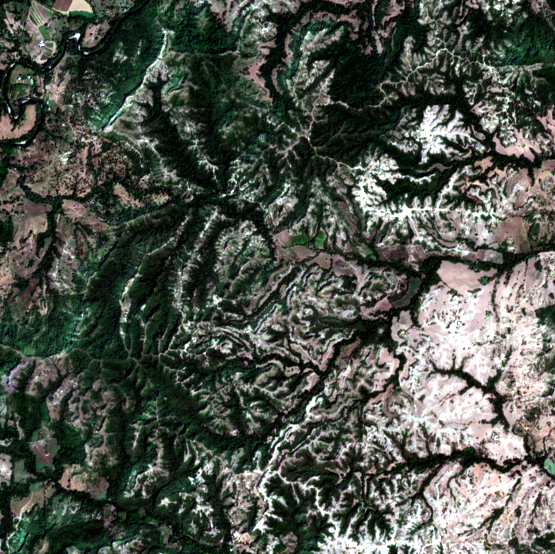

In [ ]:
# ============================================================
# CELDA 7 — VISOR SENTINEL-2
# ARMERO GUAYABAL
# ============================================================

import folium
import numpy as np
from folium.raster_layers import ImageOverlay
from IPython.display import display

print("=" * 70)
print("CELDA 7 — VISOR SENTINEL-2")
print("=" * 70)


# ------------------------------------------------------------
# 1. EXTRAER RGB
# ------------------------------------------------------------

# Orden de nuestras 12 bandas:
#
# 0 B01
# 1 B02 BLUE
# 2 B03 GREEN
# 3 B04 RED
#
# Para RGB:
# RED   = 3
# GREEN = 2
# BLUE  = 1

blue = s2_full[1]
green = s2_full[2]
red = s2_full[3]


# ------------------------------------------------------------
# 2. CONSTRUIR RGB
# ------------------------------------------------------------

rgb = np.stack(
    [
        red,
        green,
        blue
    ],
    axis=-1
)


# ------------------------------------------------------------
# 3. MEJORAR VISUALIZACIÓN
# ------------------------------------------------------------

def stretch_rgb(arr):

    salida = np.zeros_like(arr)

    for i in range(3):

        banda = arr[:, :, i]

        p2 = np.percentile(
            banda,
            2
        )

        p98 = np.percentile(
            banda,
            98
        )

        if p98 > p2:

            salida[:, :, i] = (
                banda - p2
            ) / (
                p98 - p2
            )

    return np.clip(
        salida,
        0,
        1
    )


rgb_visual = stretch_rgb(
    rgb
)


# ------------------------------------------------------------
# 4. CONVERTIR A PNG
# ------------------------------------------------------------

rgb_uint8 = (
    rgb_visual * 255
).astype(
    np.uint8
)


# ------------------------------------------------------------
# 5. CREAR MAPA
# ------------------------------------------------------------

m7 = folium.Map(
    location=[
        armero_lat,
        armero_lon
    ],
    zoom_start=11,
    tiles=None,
    control_scale=True
)


# ------------------------------------------------------------
# 6. MAPA BASE
# ------------------------------------------------------------

folium.TileLayer(
    "OpenStreetMap",
    name="Mapa base"
).add_to(m7)


# ------------------------------------------------------------
# 7. SATÉLITE DE CONTEXTO
# ------------------------------------------------------------

folium.TileLayer(
    tiles=(
        "https://server.arcgisonline.com/"
        "ArcGIS/rest/services/"
        "World_Imagery/MapServer/tile/{z}/{y}/{x}"
    ),
    attr="Esri World Imagery",
    name="Satélite de contexto",
    overlay=False
).add_to(m7)


# ------------------------------------------------------------
# 8. SENTINEL-2
# ------------------------------------------------------------

bounds = [
    [bbox[1], bbox[0]],
    [bbox[3], bbox[2]]
]

ImageOverlay(
    image=rgb_uint8,
    bounds=bounds,
    opacity=0.85,
    name="Sentinel-2 RGB"
).add_to(m7)


# ------------------------------------------------------------
# 9. LÍMITE MUNICIPAL
# ------------------------------------------------------------

folium.GeoJson(
    armero_wgs84.__geo_interface__,
    name="Límite Armero Guayabal",
    style_function=lambda feature: {
        "color": "white",
        "weight": 3,
        "fillOpacity": 0
    }
).add_to(m7)


# ------------------------------------------------------------
# 10. CENTRO
# ------------------------------------------------------------

folium.CircleMarker(
    location=[
        armero_lat,
        armero_lon
    ],
    radius=6,
    popup=(
        "<b>Armero Guayabal</b><br>"
        "Tolima, Colombia<br><br>"
        f"Latitud: {armero_lat:.6f}<br>"
        f"Longitud: {armero_lon:.6f}"
    ),
    tooltip="Centro municipal"
).add_to(m7)


# ------------------------------------------------------------
# 11. CONTROL
# ------------------------------------------------------------

folium.LayerControl(
    collapsed=False
).add_to(m7)


m7.fit_bounds(
    bounds
)


display(m7)

In [ ]:
# ============================================================
# CELDA 8 — TERRAMIND
# GENERACIÓN MULTIMODAL
# S2L2A → NDVI + LULC + DEM
# ============================================================

import torch
from terratorch.registry import FULL_MODEL_REGISTRY

print("=" * 70)
print("CELDA 8 — TERRAMIND GENERATIVE MODEL")
print("=" * 70)


# ------------------------------------------------------------
# 1. VERIFICAR ENTRADA
# ------------------------------------------------------------

print("\nEntrada recibida:")

print(
    "Shape:",
    s2_input.shape
)


expected_shape = (
    1,
    12,
    224,
    224
)

if tuple(s2_input.shape) != expected_shape:

    raise ValueError(
        f"Entrada incompatible.\n"
        f"Esperada: {expected_shape}\n"
        f"Obtenida: {tuple(s2_input.shape)}"
    )

print(
    "✓ Entrada [1,12,224,224] confirmada."
)


# ------------------------------------------------------------
# 2. DEVICE
# ------------------------------------------------------------

device = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

print(
    "\nDispositivo:",
    device
)


# ------------------------------------------------------------
# 3. CARGAR TERRAMIND
# ------------------------------------------------------------

print(
    "\nCargando TerraMind..."
)

model = FULL_MODEL_REGISTRY.build(
    "terramind_v1_base_generate",
    modalities=["S2L2A"],
    output_modalities=[
        "NDVI",
        "LULC",
        "DEM"
    ],
    pretrained=True,
    standardize=True,
    timesteps=10
)


model = model.to(
    device
)

model.eval()


print(
    "✓ TerraMind cargado."
)


# ------------------------------------------------------------
# 4. PREPARAR ENTRADA
# ------------------------------------------------------------

s2_input_device = (
    s2_input.to(device)
)


# ------------------------------------------------------------
# 5. GENERACIÓN
# ------------------------------------------------------------

print(
    "\nGenerando modalidades..."
)

with torch.no_grad():

    generated = model(
        {
            "S2L2A": s2_input_device
        },
        verbose=True
    )


# ------------------------------------------------------------
# 6. RESULTADOS
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("GENERACIÓN FINALIZADA")
print("=" * 70)


for clave, valor in generated.items():

    print(
        f"\n{clave}"
    )

    print(
        "Tipo:",
        type(valor)
    )

    if hasattr(valor, "shape"):

        print(
            "Shape:",
            valor.shape
        )

CELDA 8 — TERRAMIND GENERATIVE MODEL

Entrada recibida:
Shape: torch.Size([1, 12, 224, 224])
✓ Entrada [1,12,224,224] confirmada.

Dispositivo: cuda

Cargando TerraMind...
✓ TerraMind cargado.

Generando modalidades...


100%|██████████| 10/10 [00:00<00:00, 17.01it/s]


GENERACIÓN FINALIZADA

NDVI
Tipo: <class 'torch.Tensor'>
Shape: torch.Size([1, 1, 224, 224])

LULC
Tipo: <class 'torch.Tensor'>
Shape: torch.Size([1, 10, 224, 224])

DEM
Tipo: <class 'torch.Tensor'>
Shape: torch.Size([1, 1, 224, 224])


CELDA 9 — TERRAMIND MULTIMODAL EXPLORER
ARMERO GUAYABAL — TOLIMA

RESULTADOS TERRAMIND
------------------------------------------------------------
NDVI: (224, 224)
DEM: (224, 224)
LULC: (10, 224, 224)

NDVI
------------------------------------------------------------
Mínimo   : 0.1529
Máximo   : 0.1676
Promedio : 0.1592

DEM
------------------------------------------------------------
Mínimo   : -0.1131
Máximo   : 10.5383
Promedio : 1.4304



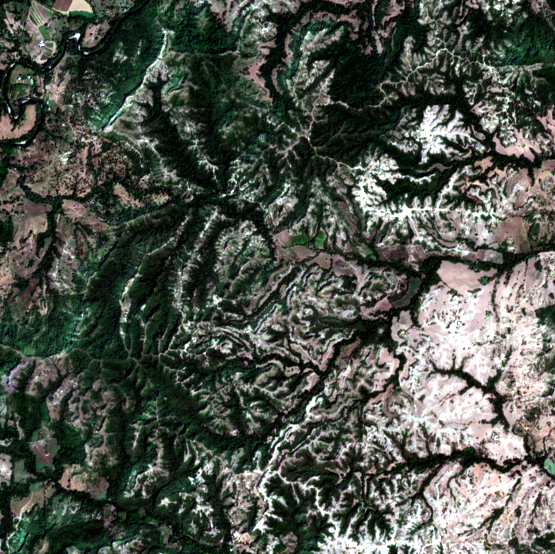
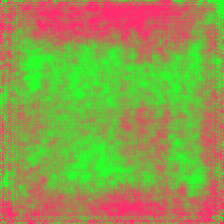
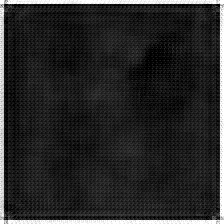

In [ ]:
# ============================================================
# CELDA 9 — TERRAMIND MULTIMODAL EXPLORER
# VISUALIZACIÓN MEJORADA
# ============================================================

import folium
import numpy as np
import torch

from folium.raster_layers import ImageOverlay
from IPython.display import display, HTML

print("=" * 70)
print("CELDA 9 — TERRAMIND MULTIMODAL EXPLORER")
print("ARMERO GUAYABAL — TOLIMA")
print("=" * 70)


# ============================================================
# 1. CONVERTIR RESULTADOS
# ============================================================

def convertir_numpy(x):

    if isinstance(x, torch.Tensor):
        return x.detach().cpu().numpy()

    return np.asarray(x)


ndvi_tm = convertir_numpy(
    generated["NDVI"]
)

dem_tm = convertir_numpy(
    generated["DEM"]
)

lulc_tm = convertir_numpy(
    generated["LULC"]
)


# ============================================================
# 2. REDUCIR DIMENSIONES
# ============================================================

ndvi_tm = np.squeeze(
    ndvi_tm
)

dem_tm = np.squeeze(
    dem_tm
)

lulc_tm = np.squeeze(
    lulc_tm,
    axis=0
)


# ============================================================
# 3. INFORMACIÓN
# ============================================================

print("\nRESULTADOS TERRAMIND")
print("-" * 60)

print(
    "NDVI:",
    ndvi_tm.shape
)

print(
    "DEM:",
    dem_tm.shape
)

print(
    "LULC:",
    lulc_tm.shape
)


# ============================================================
# 4. ESTADÍSTICAS
# ============================================================

ndvi_valid = ndvi_tm[
    np.isfinite(ndvi_tm)
]

dem_valid = dem_tm[
    np.isfinite(dem_tm)
]


print("\nNDVI")
print("-" * 60)

print(
    f"Mínimo   : {ndvi_valid.min():.4f}"
)

print(
    f"Máximo   : {ndvi_valid.max():.4f}"
)

print(
    f"Promedio : {ndvi_valid.mean():.4f}"
)


print("\nDEM")
print("-" * 60)

print(
    f"Mínimo   : {dem_valid.min():.4f}"
)

print(
    f"Máximo   : {dem_valid.max():.4f}"
)

print(
    f"Promedio : {dem_valid.mean():.4f}"
)


# ============================================================
# 5. NORMALIZACIÓN
# ============================================================

def normalizar(arr):

    arr = np.nan_to_num(
        arr,
        nan=0,
        posinf=0,
        neginf=0
    )

    minimo = np.percentile(
        arr,
        2
    )

    maximo = np.percentile(
        arr,
        98
    )

    if maximo <= minimo:

        return np.zeros_like(arr)

    salida = (
        arr - minimo
    ) / (
        maximo - minimo
    )

    return np.clip(
        salida,
        0,
        1
    )


ndvi_norm = normalizar(
    ndvi_tm
)

dem_norm = normalizar(
    dem_tm
)


# ============================================================
# 6. NDVI — PALETA TEMÁTICA
# ============================================================
#
# No estamos creando clases.
#
# Solamente estamos usando una escala visual continua
# para facilitar la interpretación del raster.
#
# Bajo → tonos oscuros
# Alto → tonos verdes
# ============================================================

def ndvi_rgba(arr):

    arr = np.clip(
        arr,
        0,
        1
    )

    h, w = arr.shape

    rgba = np.zeros(
        (h, w, 4),
        dtype=np.uint8
    )

    # Rojo → valores bajos
    rgba[:, :, 0] = (
        255 * (1 - arr)
    ).astype(
        np.uint8
    )

    # Verde → valores altos
    rgba[:, :, 1] = (
        255 * arr
    ).astype(
        np.uint8
    )

    # Azul moderado
    rgba[:, :, 2] = (
        80 * (1 - arr)
    ).astype(
        np.uint8
    )

    # Transparencia
    rgba[:, :, 3] = 210

    return rgba


ndvi_rgba_img = ndvi_rgba(
    ndvi_norm
)


# ============================================================
# 7. DEM — RELIEVE EN ESCALA VISUAL
# ============================================================

dem_gray = (
    dem_norm * 255
).astype(
    np.uint8
)


# ============================================================
# 8. CENTRO MUNICIPAL
# ============================================================

centro = (
    armero_wgs84
    .geometry
    .iloc[0]
    .centroid
)

armero_lat = centro.y
armero_lon = centro.x


# ============================================================
# 9. EXTENSIÓN DEL PATCH
# ============================================================

patch_bounds = [
    [bbox[1], bbox[0]],
    [bbox[3], bbox[2]]
]


# ============================================================
# 10. MAPA
# ============================================================

m9 = folium.Map(
    location=[
        armero_lat,
        armero_lon
    ],
    zoom_start=13,
    tiles=None,
    control_scale=True
)


# ============================================================
# 11. OPENSTREETMAP
# ============================================================

folium.TileLayer(
    "OpenStreetMap",
    name="Mapa base"
).add_to(m9)


# ============================================================
# 12. SATÉLITE
# ============================================================

folium.TileLayer(
    tiles=(
        "https://server.arcgisonline.com/"
        "ArcGIS/rest/services/"
        "World_Imagery/MapServer/tile/{z}/{y}/{x}"
    ),
    attr="Esri World Imagery",
    name="Satélite de contexto",
    overlay=False
).add_to(m9)


# ============================================================
# 13. SENTINEL-2 RGB
# ============================================================

if "rgb_uint8" in globals():

    ImageOverlay(
        image=rgb_uint8,
        bounds=patch_bounds,
        opacity=0.90,
        name="Sentinel-2 RGB"
    ).add_to(m9)


# ============================================================
# 14. TERRAMIND NDVI
# ============================================================

ImageOverlay(
    image=ndvi_rgba_img,
    bounds=patch_bounds,
    opacity=0.75,
    name="TerraMind — NDVI"
).add_to(m9)


# ============================================================
# 15. TERRAMIND DEM
# ============================================================

ImageOverlay(
    image=dem_gray,
    bounds=patch_bounds,
    opacity=0.70,
    name="TerraMind — DEM"
).add_to(m9)


# ============================================================
# 16. LÍMITE MUNICIPAL
# ============================================================

folium.GeoJson(
    armero_wgs84.__geo_interface__,
    name="Límite municipal",
    style_function=lambda feature: {
        "color": "white",
        "weight": 3,
        "fillOpacity": 0
    }
).add_to(m9)


# ============================================================
# 17. CENTRO
# ============================================================

folium.CircleMarker(
    location=[
        armero_lat,
        armero_lon
    ],
    radius=6,
    popup=(
        "<b>Armero Guayabal</b><br>"
        "Tolima, Colombia<br><br>"
        "TerraMind Multimodal Explorer"
    ),
    tooltip="Centro municipal"
).add_to(m9)


# ============================================================
# 18. CONTROL DE CAPAS
# ============================================================

folium.LayerControl(
    collapsed=False
).add_to(m9)


# ============================================================
# 19. AJUSTAR VISTA
# ============================================================

m9.fit_bounds(
    patch_bounds
)


# ============================================================
# 20. PANEL
# ============================================================

panel = f"""
<div style="
position: fixed;
bottom: 25px;
left: 25px;
z-index: 9999;
background: white;
padding: 16px;
border-radius: 12px;
box-shadow: 0 2px 10px rgba(0,0,0,0.25);
font-family: Arial;
width: 270px;
">

<div style="
font-size:18px;
font-weight:bold;
margin-bottom:8px;
">
TerraMind Explorer
</div>

<div>
<b>Armero Guayabal</b>
</div>

<div>
Tolima, Colombia
</div>

<hr>

<div>
<b>NDVI TerraMind</b>
</div>

<div>
Mínimo: {ndvi_valid.min():.3f}
</div>

<div>
Promedio: {ndvi_valid.mean():.3f}
</div>

<div>
Máximo: {ndvi_valid.max():.3f}
</div>

<hr>

<div>
<b>DEM TerraMind</b>
</div>

<div>
Representación generada por IA
</div>

<hr>

<div style="
font-size:11px;
color:#666;
">
LULC generado: 10 canales tokenizados.
No se representa como RGB.
</div>

</div>
"""


display(
    HTML(panel)
)

display(
    m9
)

 COMPARACIÓN ESPACIAL
SENTINEL-2 vs TERRAMIND

NDVI TerraMind:
Shape: (224, 224)

NDVI Sentinel-2:
Shape: (224, 224)

Diferencia espacial calculada.
Mínimo : 0.0
Máximo : 1.0
Media  : 0.3145153



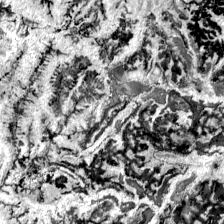
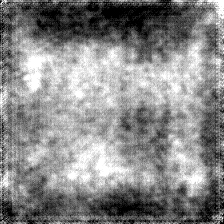
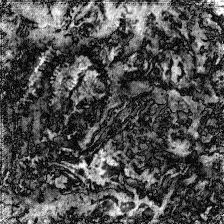

In [ ]:
# ============================================================
# CELDA 10 — COMPARACIÓN ESPACIAL
# SENTINEL-2 vs TERRAMIND
# ============================================================

import numpy as np
import torch
import folium
from folium.raster_layers import ImageOverlay
from IPython.display import display, HTML

print("=" * 70)
print(" COMPARACIÓN ESPACIAL")
print("SENTINEL-2 vs TERRAMIND")
print("=" * 70)

# ------------------------------------------------------------
# 1. CONVERTIR NDVI TERRAMIND A NUMPY
# ------------------------------------------------------------

ndvi_tm = generated["NDVI"]

if isinstance(ndvi_tm, torch.Tensor):
    ndvi_tm = ndvi_tm.detach().cpu().numpy()

ndvi_tm = np.squeeze(ndvi_tm)

print("\nNDVI TerraMind:")
print("Shape:", ndvi_tm.shape)


# ------------------------------------------------------------
# 2. CALCULAR NDVI REAL DESDE SENTINEL-2
# ------------------------------------------------------------

# Recordatorio:
# B04 = rojo
# B08 = infrarrojo cercano

red = s2_patch[2].detach().cpu().numpy()
nir = s2_patch[7].detach().cpu().numpy()

denominador = nir + red

ndvi_s2 = np.divide(
    nir - red,
    denominador,
    out=np.zeros_like(nir, dtype=np.float32),
    where=denominador != 0
)

ndvi_s2 = np.clip(ndvi_s2, -1, 1)

print("\nNDVI Sentinel-2:")
print("Shape:", ndvi_s2.shape)


# ------------------------------------------------------------
# 3. NORMALIZACIÓN VISUAL
# ------------------------------------------------------------

def normalizar_percentiles(arr):
    arr = np.nan_to_num(arr, nan=0, posinf=0, neginf=0)

    p2 = np.percentile(arr, 2)
    p98 = np.percentile(arr, 98)

    if p98 <= p2:
        return np.zeros_like(arr)

    resultado = (arr - p2) / (p98 - p2)

    return np.clip(resultado, 0, 1)


s2_vis = normalizar_percentiles(ndvi_s2)
tm_vis = normalizar_percentiles(ndvi_tm)


# ------------------------------------------------------------
# 4. DIFERENCIA ESPACIAL
# ------------------------------------------------------------

diferencia = np.abs(s2_vis - tm_vis)

print("\nDiferencia espacial calculada.")
print("Mínimo :", diferencia.min())
print("Máximo :", diferencia.max())
print("Media  :", diferencia.mean())


# ------------------------------------------------------------
# 5. CREAR MAPA
# ------------------------------------------------------------

centro = armero_wgs84.geometry.iloc[0].centroid

armero_lat = centro.y
armero_lon = centro.x

patch_bounds = [
    [bbox[1], bbox[0]],
    [bbox[3], bbox[2]]
]

m10 = folium.Map(
    location=[armero_lat, armero_lon],
    zoom_start=13,
    tiles=None,
    control_scale=True
)

# Mapa base
folium.TileLayer(
    "OpenStreetMap",
    name="Mapa base"
).add_to(m10)

# Imagen satelital
folium.TileLayer(
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}",
    attr="Esri World Imagery",
    name="Satélite",
    overlay=False
).add_to(m10)


# ------------------------------------------------------------
# 6. OVERLAYS
# ------------------------------------------------------------

ImageOverlay(
    image=s2_vis,
    bounds=patch_bounds,
    opacity=0.70,
    name="NDVI Sentinel-2"
).add_to(m10)

ImageOverlay(
    image=tm_vis,
    bounds=patch_bounds,
    opacity=0.70,
    name="NDVI TerraMind"
).add_to(m10)

ImageOverlay(
    image=diferencia,
    bounds=patch_bounds,
    opacity=0.80,
    name="Discrepancia espacial"
).add_to(m10)


# ------------------------------------------------------------
# 7. LÍMITE MUNICIPAL
# ------------------------------------------------------------

folium.GeoJson(
    armero_wgs84.__geo_interface__,
    name="Límite municipal",
    style_function=lambda feature: {
        "color": "white",
        "weight": 3,
        "fillOpacity": 0
    }
).add_to(m10)


# ------------------------------------------------------------
# 8. CENTRO MUNICIPAL
# ------------------------------------------------------------

folium.Marker(
    [armero_lat, armero_lon],
    popup="""
    <b>Armero Guayabal</b><br>
    Tolima, Colombia<br><br>
    Comparación Sentinel-2 / TerraMind
    """,
    tooltip="Armero Guayabal"
).add_to(m10)


# ------------------------------------------------------------
# 9. CONTROL DE CAPAS
# ------------------------------------------------------------

folium.LayerControl(
    collapsed=False
).add_to(m10)

m10.fit_bounds(patch_bounds)

display(m10)

 GEOVISOR PROFESIONAL
SENTINEL-2 vs TERRAMIND
ARMERO GUAYABAL — TOLIMA



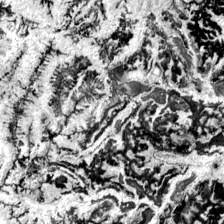
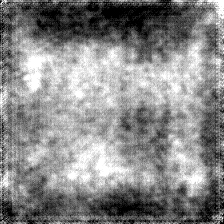
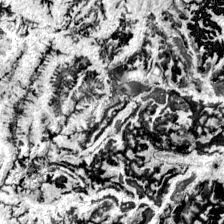
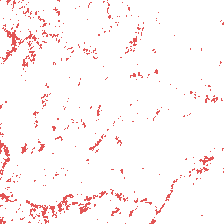

In [ ]:
# ============================================================
# CELDA 10 — GEOVISOR PROFESIONAL
# MAPA IZQUIERDA + PANEL DE ANÁLISIS DERECHA
# ============================================================

import numpy as np
import torch
import folium

from folium.raster_layers import ImageOverlay
from folium.plugins import Fullscreen, MousePosition
from branca.element import Element

from IPython.display import display


print("=" * 75)
print(" GEOVISOR PROFESIONAL")
print("SENTINEL-2 vs TERRAMIND")
print("ARMERO GUAYABAL — TOLIMA")
print("=" * 75)


# ============================================================
# 1. NDVI TERRAMIND
# ============================================================

ndvi_tm = generated["NDVI"]

if isinstance(ndvi_tm, torch.Tensor):
    ndvi_tm = ndvi_tm.detach().cpu().numpy()

ndvi_tm = np.squeeze(ndvi_tm).astype(np.float32)


# ============================================================
# 2. NDVI SENTINEL-2
# ============================================================

red = s2_patch[3].detach().cpu().numpy()
nir = s2_patch[7].detach().cpu().numpy()

ndvi_s2 = np.divide(
    nir - red,
    nir + red,
    out=np.zeros_like(nir, dtype=np.float32),
    where=(nir + red) != 0
)

ndvi_s2 = np.clip(ndvi_s2, -1, 1)


# ============================================================
# 3. VALIDACIÓN
# ============================================================

validos = (
    np.isfinite(ndvi_s2) &
    np.isfinite(ndvi_tm)
)

s2_valid = ndvi_s2[validos]
tm_valid = ndvi_tm[validos]


# ============================================================
# 4. ESTADÍSTICAS
# ============================================================

media_s2 = float(np.mean(s2_valid))
media_tm = float(np.mean(tm_valid))

min_s2 = float(np.min(s2_valid))
max_s2 = float(np.max(s2_valid))

min_tm = float(np.min(tm_valid))
max_tm = float(np.max(tm_valid))


# ============================================================
# 5. CORRELACIÓN
# ============================================================

if (
    len(s2_valid) > 1 and
    np.std(s2_valid) > 0 and
    np.std(tm_valid) > 0
):

    correlacion = float(
        np.corrcoef(
            s2_valid,
            tm_valid
        )[0, 1]
    )

else:

    correlacion = np.nan


# ============================================================
# 6. DIFERENCIA ABSOLUTA
# ============================================================

diferencia = np.abs(
    ndvi_s2 - ndvi_tm
)

diferencia[
    ~validos
] = np.nan

dif_valid = diferencia[
    np.isfinite(diferencia)
]

dif_media = float(
    np.mean(dif_valid)
)

dif_max = float(
    np.max(dif_valid)
)

p90 = float(
    np.percentile(
        dif_valid,
        90
    )
)

p95 = float(
    np.percentile(
        dif_valid,
        95
    )
)


# ============================================================
# 7. ZONAS P95
# ============================================================

zonas_p95 = (
    diferencia >= p95
)

cantidad_p95 = int(
    zonas_p95.sum()
)

porcentaje_p95 = (
    cantidad_p95 /
    zonas_p95.size
) * 100


# ============================================================
# 8. NORMALIZACIÓN VISUAL
# ============================================================

def normalizar_visual(arr):

    arr = np.nan_to_num(
        arr,
        nan=0,
        posinf=0,
        neginf=0
    )

    p2 = np.percentile(
        arr,
        2
    )

    p98 = np.percentile(
        arr,
        98
    )

    if p98 <= p2:
        return np.zeros_like(arr)

    return np.clip(
        (arr - p2) /
        (p98 - p2),
        0,
        1
    )


s2_visual = normalizar_visual(
    ndvi_s2
)

tm_visual = normalizar_visual(
    ndvi_tm
)

dif_visual = normalizar_visual(
    diferencia
)


# ============================================================
# 9. MÁSCARA P95
# ============================================================

mascara_p95 = np.zeros(
    (
        zonas_p95.shape[0],
        zonas_p95.shape[1],
        4
    ),
    dtype=np.uint8
)

mascara_p95[zonas_p95, 0] = 220
mascara_p95[zonas_p95, 1] = 50
mascara_p95[zonas_p95, 2] = 50
mascara_p95[zonas_p95, 3] = 210


# ============================================================
# 10. CENTRO Y EXTENSIÓN
# ============================================================

centro = (
    armero_wgs84
    .geometry
    .iloc[0]
    .centroid
)

armero_lat = centro.y
armero_lon = centro.x

patch_bounds = [
    [bbox[1], bbox[0]],
    [bbox[3], bbox[2]]
]


# ============================================================
# 11. MAPA
# ============================================================

m10 = folium.Map(
    location=[
        armero_lat,
        armero_lon
    ],
    zoom_start=13,
    tiles=None,
    control_scale=True,
    prefer_canvas=True
)


# ============================================================
# 12. MAPAS BASE
# ============================================================

folium.TileLayer(
    "OpenStreetMap",
    name="Cartografía",
    overlay=False
).add_to(m10)


folium.TileLayer(
    tiles=(
        "https://server.arcgisonline.com/"
        "ArcGIS/rest/services/World_Imagery/"
        "MapServer/tile/{z}/{y}/{x}"
    ),
    attr="Esri World Imagery",
    name="Imagen satelital",
    overlay=False
).add_to(m10)


# ============================================================
# 13. CAPAS DE ANÁLISIS
# ============================================================

ImageOverlay(
    image=s2_visual,
    bounds=patch_bounds,
    opacity=0.75,
    name="NDVI — Sentinel-2"
).add_to(m10)


ImageOverlay(
    image=tm_visual,
    bounds=patch_bounds,
    opacity=0.75,
    name="NDVI — TerraMind"
).add_to(m10)


ImageOverlay(
    image=dif_visual,
    bounds=patch_bounds,
    opacity=0.80,
    name="Discrepancia absoluta"
).add_to(m10)


ImageOverlay(
    image=mascara_p95,
    bounds=patch_bounds,
    opacity=0.85,
    name="Alta discrepancia — P95"
).add_to(m10)


# ============================================================
# 14. LÍMITE MUNICIPAL
# ============================================================

folium.GeoJson(
    armero_wgs84.__geo_interface__,
    name="Límite municipal",
    style_function=lambda feature: {
        "color": "#FFFFFF",
        "weight": 3,
        "fillOpacity": 0,
        "dashArray": "7,5"
    }
).add_to(m10)


# ============================================================
# 15. CENTROIDE
# ============================================================

folium.CircleMarker(
    location=[
        armero_lat,
        armero_lon
    ],
    radius=5,
    weight=2,
    fill=True,
    fill_opacity=1,
    tooltip="Centro de Armero Guayabal"
).add_to(m10)


# ============================================================
# 16. CONTROL DE CAPAS
# ============================================================

folium.LayerControl(
    collapsed=False,
    position="topright"
).add_to(m10)


# ============================================================
# 17. HERRAMIENTAS
# ============================================================

Fullscreen(
    position="topright"
).add_to(m10)


MousePosition(
    position="topright",
    separator=" | ",
    prefix="Coordenadas:",
    num_digits=5
).add_to(m10)


m10.fit_bounds(
    patch_bounds
)


# ============================================================
# 18. TÍTULO SUPERIOR DEL MAPA
# ============================================================

titulo = """

<div style="
position: fixed;
top: 15px;
left: 20px;
z-index: 9999;

background: rgba(255,255,255,0.96);

padding: 12px 18px;

border-radius: 8px;

box-shadow:
0 2px 8px rgba(0,0,0,0.20);

font-family: Arial, sans-serif;

">

<div style="
font-size:18px;
font-weight:bold;
">
ANÁLISIS MULTIMODAL
</div>

<div style="
font-size:12px;
color:#555;
margin-top:3px;
">
Sentinel-2 + TerraMind
</div>

</div>

"""

m10.get_root().html.add_child(
    Element(titulo)
)


# ============================================================
# 19. PANEL DERECHO
# ============================================================

panel = f"""

<style>

#panel-terramind {{

position: fixed;

top: 0;
right: 0;

width: 360px;
height: 100vh;

background: #ffffff;

z-index: 10000;

box-shadow:
-4px 0px 15px rgba(0,0,0,0.18);

font-family:
Arial, Helvetica, sans-serif;

overflow-y: auto;

}}

.panel-header {{

padding: 22px 22px 18px 22px;

border-bottom:
1px solid #e5e5e5;

}}

.panel-title {{

font-size: 21px;
font-weight: 700;

color: #1f2937;

}}

.panel-subtitle {{

font-size: 12px;

color: #6b7280;

margin-top: 5px;

}}

.panel-section {{

padding: 18px 22px;

border-bottom:
1px solid #eeeeee;

}}

.section-title {{

font-size: 12px;

font-weight: 700;

letter-spacing: 0.7px;

color: #6b7280;

margin-bottom: 12px;

text-transform: uppercase;

}}

.stat-grid {{

display: grid;

grid-template-columns:
1fr 1fr;

gap: 10px;

}}

.stat-card {{

border:
1px solid #e5e7eb;

border-radius: 8px;

padding: 12px;

background: #fafafa;

}}

.stat-label {{

font-size: 10px;

color: #6b7280;

}}

.stat-value {{

font-size: 22px;

font-weight: 700;

color: #111827;

margin-top: 4px;

}}

.stat-small {{

font-size: 10px;

color: #6b7280;

margin-top: 2px;

}}


.info-row {{

display:flex;

justify-content:space-between;

padding:5px 0;

font-size:12px;

}}

.info-label {{

color:#6b7280;

}}

.info-value {{

font-weight:600;

color:#374151;

}}

.note {{

font-size:11px;

line-height:1.55;

color:#6b7280;

}}

.footer {{

padding:18px 22px;

font-size:10px;

color:#9ca3af;

line-height:1.5;

}}

</style>


<div id="panel-terramind">


<!-- ENCABEZADO -->

<div class="panel-header">

<div class="panel-title">
TerraMind Explorer
</div>

<div class="panel-subtitle">
Análisis espacial multimodal
</div>

<div class="panel-subtitle">
Armero Guayabal · Tolima · Colombia
</div>

</div>


<!-- RESULTADOS PRINCIPALES -->

<div class="panel-section">

<div class="section-title">
Resultados principales
</div>


<div class="stat-grid">


<div class="stat-card">

<div class="stat-label">
NDVI SENTINEL-2
</div>

<div class="stat-value">
{media_s2:.3f}
</div>

<div class="stat-small">
promedio
</div>

</div>


<div class="stat-card">

<div class="stat-label">
NDVI TERRAMIND
</div>

<div class="stat-value">
{media_tm:.3f}
</div>

<div class="stat-small">
promedio
</div>

</div>


<div class="stat-card">

<div class="stat-label">
CORRELACIÓN
</div>

<div class="stat-value">
{correlacion:.3f}
</div>

<div class="stat-small">
espacial
</div>

</div>


<div class="stat-card">

<div class="stat-label">
DIFERENCIA
</div>

<div class="stat-value">
{dif_media:.3f}
</div>

<div class="stat-small">
promedio absoluta
</div>

</div>

</div>

</div>


<!-- NDVI -->

<div class="panel-section">

<div class="section-title">
Distribución NDVI
</div>


<div class="info-row">
<span class="info-label">
Sentinel-2 mínimo
</span>

<span class="info-value">
{min_s2:.3f}
</span>
</div>


<div class="info-row">
<span class="info-label">
Sentinel-2 máximo
</span>

<span class="info-value">
{max_s2:.3f}
</span>
</div>


<div class="info-row">
<span class="info-label">
TerraMind mínimo
</span>

<span class="info-value">
{min_tm:.3f}
</span>
</div>


<div class="info-row">
<span class="info-label">
TerraMind máximo
</span>

<span class="info-value">
{max_tm:.3f}
</span>
</div>

</div>


<!-- INFORMACIÓN DEL PRODUCTO -->

<div class="panel-section">

<div class="section-title">
Información cartográfica
</div>


<div class="info-row">
<span class="info-label">
Área de estudio
</span>

<span class="info-value">
Armero Guayabal
</span>
</div>


<div class="info-row">
<span class="info-label">
Departamento
</span>

<span class="info-value">
Tolima
</span>
</div>


<div class="info-row">
<span class="info-label">
Sensor
</span>

<span class="info-value">
Sentinel-2 L2A
</span>
</div>


<div class="info-row">
<span class="info-label">
Modelo
</span>

<span class="info-value">
TerraMind
</span>
</div>


<div class="info-row">
<span class="info-label">
Resolución
</span>

<span class="info-value">
10 m
</span>
</div>


<div class="info-row">
<span class="info-label">
Ventana
</span>

<span class="info-value">
224 × 224 px
</span>
</div>


<div class="info-row">
<span class="info-label">
Extensión
</span>

<span class="info-value">
2.24 × 2.24 km
</span>
</div>

</div>


<!-- DISCREPANCIA -->

<div class="panel-section">

<div class="section-title">
Discrepancia espacial
</div>


<div class="info-row">
<span class="info-label">
P90
</span>

<span class="info-value">
{p90:.3f}
</span>
</div>


<div class="info-row">
<span class="info-label">
P95
</span>

<span class="info-value">
{p95:.3f}
</span>
</div>


<div class="info-row">
<span class="info-label">
Máximo
</span>

<span class="info-value">
{dif_max:.3f}
</span>
</div>


<div class="info-row">
<span class="info-label">
Píxeles P95
</span>

<span class="info-value">
{cantidad_p95:,}
</span>
</div>


<div class="info-row">
<span class="info-label">
Proporción
</span>

<span class="info-value">
{porcentaje_p95:.2f}%
</span>
</div>

</div>


<!-- METODOLOGÍA -->

<div class="panel-section">

<div class="section-title">
Metodología
</div>


<div class="note">

<b>01</b> Sentinel-2 proporciona la
información multiespectral de entrada.

<br><br>

<b>02</b> TerraMind genera representaciones
multimodales a partir de la información
satelital.

<br><br>

<b>03</b> El NDVI de referencia se calcula
directamente utilizando las bandas B04
y B08.

<br><br>

<b>04</b> Se compara espacialmente la
representación NDVI de TerraMind con
la referencia Sentinel-2.

<br><br>

<b>05</b> El percentil 95 permite localizar
las zonas con mayor discrepancia dentro
del parche analizado.

</div>

</div>


<!-- NOTA -->

<div class="panel-section">

<div class="section-title">
Consideración técnica
</div>

<div class="note">

Las escalas cromáticas del mapa son de
visualización relativa.

Las zonas P95 representan áreas de
mayor discrepancia espacial dentro
del área analizada.

Este resultado es exploratorio y no
corresponde por sí mismo a una
detección de cambio multitemporal ni
a una validación de precisión del modelo.

</div>

</div>


<!-- FUENTES -->

<div class="footer">

<b>Fuentes de datos</b><br>

Sentinel-2 L2A · Microsoft Planetary Computer<br>
TerraMind · TerraTorch / IBM<br>
Cartografía base · OpenStreetMap<br>
Imagen satelital · Esri World Imagery

</div>


</div>

"""


m10.get_root().html.add_child(
    Element(panel)
)


# ============================================================
# 20. AJUSTAR EL MAPA PARA DEJAR ESPACIO AL PANEL
# ============================================================

m10.get_root().html.add_child(
    Element("""
    <style>

    .leaflet-control-container {
        margin-right: 370px !important;
    }

    .leaflet-top {
        margin-right: 370px !important;
    }

    .leaflet-bottom {
        margin-right: 370px !important;
    }

    </style>
    """)
)


# ============================================================
# 21. MOSTRAR
# ============================================================

display(m10)

CELDA 11 — ANÁLISIS ESTADÍSTICO
SENTINEL-2 vs TERRAMIND
ARMERO GUAYABAL — TOLIMA


,Estadístico,Sentinel-2,TerraMind,Discrepancia
0,N,50176.0000,50176.0000,50176.0000
1,Mínimo,0.0645,0.1529,0.0000
2,Máximo,0.6198,0.1676,0.4608
3,Media,0.3803,0.1592,0.2219
4,Mediana,0.3984,0.1593,0.2389
5,Desv. estándar,0.1137,0.0012,0.1122
6,P5,0.1877,0.1571,0.0317
7,P10,0.2168,0.1575,0.0577
8,P25,0.2848,0.1583,0.1255
9,P50,0.3984,0.1593,0.2389



MÉTRICAS DE COMPARACIÓN
Número de píxeles válidos:       50,176
MAE:                              0.2219
RMSE:                             0.2486
Sesgo TerraMind - Sentinel-2:    -0.2211
Correlación de Pearson:           -0.0691
R² descriptivo:                   0.0048
Diferencia mediana:               0.2389
Diferencia P90:                   0.3571
Diferencia P95:                   0.3741
Diferencia P99:                   0.4031

INFORMACIÓN ESPACIAL
Dimensión raster:                224 × 224 píxeles
Resolución aproximada:            10 m
Área aproximada analizada:        501.76 ha
Píxeles con discrepancia P95:     2,509
Área aproximada P95:              25.09 ha
Proporción espacial P95:          5.00%


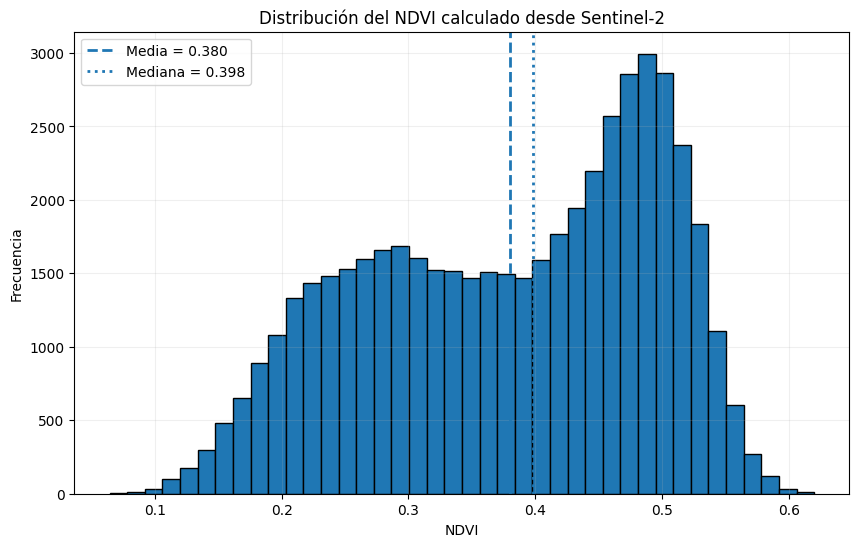

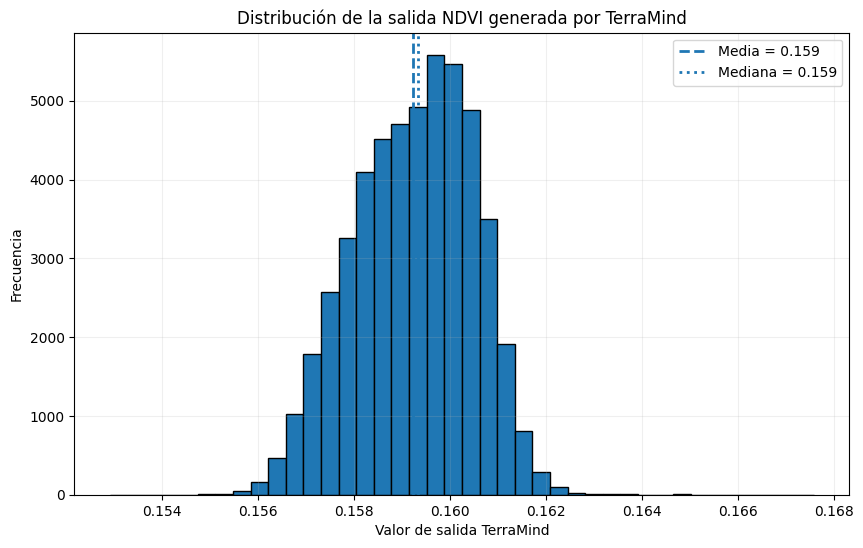

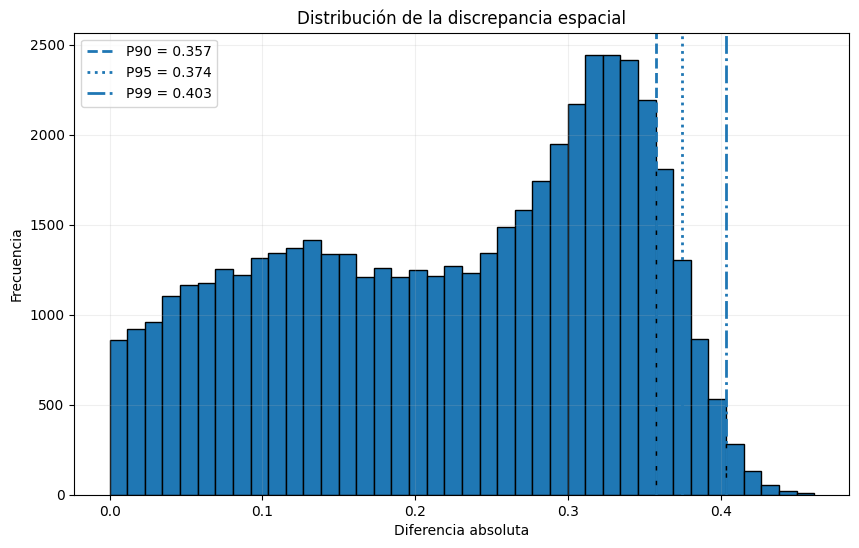

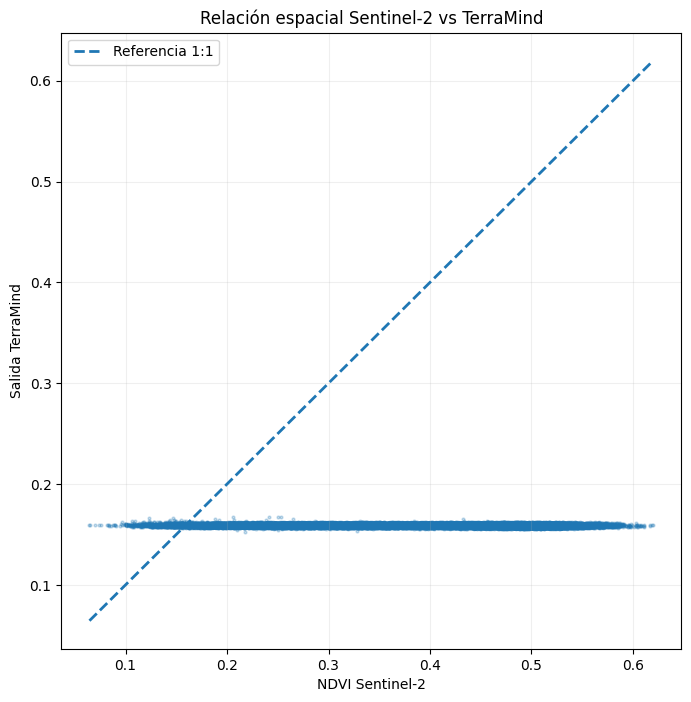


RESUMEN DEL ANÁLISIS
Se analizaron 50,176 píxeles válidos en un parche de 224 × 224 píxeles.
La diferencia absoluta media fue de 0.2219 y el RMSE fue de 0.2486.
El percentil 95 de discrepancia fue 0.3741, identificando 2,509 píxeles.
Estos píxeles representan aproximadamente 5.00% del área analizada.

✓ Estadísticas y gráficos generados correctamente.


In [ ]:
# ============================================================
# ANÁLISIS ESTADÍSTICO COMPLETO
# SENTINEL-2 vs TERRAMIND
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("=" * 80)
print("CELDA 11 — ANÁLISIS ESTADÍSTICO")
print("SENTINEL-2 vs TERRAMIND")
print("ARMERO GUAYABAL — TOLIMA")
print("=" * 80)


# ============================================================
# 1. PREPARAR DATOS
# ============================================================

validos = (
    np.isfinite(ndvi_s2) &
    np.isfinite(ndvi_tm) &
    np.isfinite(diferencia)
)

s2_valid = ndvi_s2[validos].astype(float)
tm_valid = ndvi_tm[validos].astype(float)
dif_valid = diferencia[validos].astype(float)


# ============================================================
# 2. ESTADÍSTICAS DESCRIPTIVAS
# ============================================================

def estadisticas_completas(datos):

    return {
        "N": len(datos),
        "Mínimo": np.min(datos),
        "Máximo": np.max(datos),
        "Media": np.mean(datos),
        "Mediana": np.median(datos),
        "Desv. estándar": np.std(datos),
        "P5": np.percentile(datos, 5),
        "P10": np.percentile(datos, 10),
        "P25": np.percentile(datos, 25),
        "P50": np.percentile(datos, 50),
        "P75": np.percentile(datos, 75),
        "P90": np.percentile(datos, 90),
        "P95": np.percentile(datos, 95),
        "P99": np.percentile(datos, 99)
    }


stats_s2 = estadisticas_completas(s2_valid)
stats_tm = estadisticas_completas(tm_valid)
stats_dif = estadisticas_completas(dif_valid)


# ============================================================
# 3. TABLA GENERAL
# ============================================================

tabla_estadistica = pd.DataFrame({
    "Estadístico": list(stats_s2.keys()),
    "Sentinel-2": list(stats_s2.values()),
    "TerraMind": list(stats_tm.values()),
    "Discrepancia": list(stats_dif.values())
})

tabla_estadistica["Sentinel-2"] = tabla_estadistica["Sentinel-2"].round(4)
tabla_estadistica["TerraMind"] = tabla_estadistica["TerraMind"].round(4)
tabla_estadistica["Discrepancia"] = tabla_estadistica["Discrepancia"].round(4)

display(tabla_estadistica)


# ============================================================
# 4. MÉTRICAS ADICIONALES
# ============================================================

mae = np.mean(
    np.abs(s2_valid - tm_valid)
)

rmse = np.sqrt(
    np.mean(
        (s2_valid - tm_valid) ** 2
    )
)

sesgo = np.mean(
    tm_valid - s2_valid
)

correlacion_pearson = np.corrcoef(
    s2_valid,
    tm_valid
)[0, 1]

r2 = correlacion_pearson ** 2

dif_mediana = np.median(dif_valid)

dif_p90 = np.percentile(
    dif_valid,
    90
)

dif_p95 = np.percentile(
    dif_valid,
    95
)

dif_p99 = np.percentile(
    dif_valid,
    99
)


print("\n" + "=" * 80)
print("MÉTRICAS DE COMPARACIÓN")
print("=" * 80)

print(f"Número de píxeles válidos:       {len(s2_valid):,}")
print(f"MAE:                              {mae:.4f}")
print(f"RMSE:                             {rmse:.4f}")
print(f"Sesgo TerraMind - Sentinel-2:    {sesgo:.4f}")
print(f"Correlación de Pearson:           {correlacion_pearson:.4f}")
print(f"R² descriptivo:                   {r2:.4f}")
print(f"Diferencia mediana:               {dif_mediana:.4f}")
print(f"Diferencia P90:                   {dif_p90:.4f}")
print(f"Diferencia P95:                   {dif_p95:.4f}")
print(f"Diferencia P99:                   {dif_p99:.4f}")


# ============================================================
# 5. INFORMACIÓN ESPACIAL
# ============================================================

alto, ancho = ndvi_s2.shape

resolucion_aprox = 10

area_pixel_m2 = resolucion_aprox ** 2

area_total_m2 = (
    alto *
    ancho *
    area_pixel_m2
)

area_total_ha = (
    area_total_m2 / 10000
)

area_p95_ha = (
    cantidad_p95 *
    area_pixel_m2 /
    10000
)


print("\n" + "=" * 80)
print("INFORMACIÓN ESPACIAL")
print("=" * 80)

print(f"Dimensión raster:                {ancho} × {alto} píxeles")
print(f"Resolución aproximada:            {resolucion_aprox} m")
print(f"Área aproximada analizada:        {area_total_ha:.2f} ha")
print(f"Píxeles con discrepancia P95:     {cantidad_p95:,}")
print(f"Área aproximada P95:              {area_p95_ha:.2f} ha")
print(f"Proporción espacial P95:          {porcentaje_p95:.2f}%")


# ============================================================
# 6. HISTOGRAMA — SENTINEL-2
# ============================================================

plt.figure(figsize=(10, 6))

plt.hist(
    s2_valid,
    bins=40,
    edgecolor="black"
)

plt.axvline(
    np.mean(s2_valid),
    linestyle="--",
    linewidth=2,
    label=f"Media = {np.mean(s2_valid):.3f}"
)

plt.axvline(
    np.median(s2_valid),
    linestyle=":",
    linewidth=2,
    label=f"Mediana = {np.median(s2_valid):.3f}"
)

plt.title(
    "Distribución del NDVI calculado desde Sentinel-2"
)

plt.xlabel(
    "NDVI"
)

plt.ylabel(
    "Frecuencia"
)

plt.legend()

plt.grid(
    alpha=0.2
)

plt.show()


# ============================================================
# 7. HISTOGRAMA — TERRAMIND
# ============================================================

plt.figure(figsize=(10, 6))

plt.hist(
    tm_valid,
    bins=40,
    edgecolor="black"
)

plt.axvline(
    np.mean(tm_valid),
    linestyle="--",
    linewidth=2,
    label=f"Media = {np.mean(tm_valid):.3f}"
)

plt.axvline(
    np.median(tm_valid),
    linestyle=":",
    linewidth=2,
    label=f"Mediana = {np.median(tm_valid):.3f}"
)

plt.title(
    "Distribución de la salida NDVI generada por TerraMind"
)

plt.xlabel(
    "Valor de salida TerraMind"
)

plt.ylabel(
    "Frecuencia"
)

plt.legend()

plt.grid(
    alpha=0.2
)

plt.show()


# ============================================================
# 8. HISTOGRAMA — DISCREPANCIA
# ============================================================

plt.figure(figsize=(10, 6))

plt.hist(
    dif_valid,
    bins=40,
    edgecolor="black"
)

plt.axvline(
    dif_p90,
    linestyle="--",
    linewidth=2,
    label=f"P90 = {dif_p90:.3f}"
)

plt.axvline(
    dif_p95,
    linestyle=":",
    linewidth=2,
    label=f"P95 = {dif_p95:.3f}"
)

plt.axvline(
    dif_p99,
    linestyle="-.",
    linewidth=2,
    label=f"P99 = {dif_p99:.3f}"
)

plt.title(
    "Distribución de la discrepancia espacial"
)

plt.xlabel(
    "Diferencia absoluta"
)

plt.ylabel(
    "Frecuencia"
)

plt.legend()

plt.grid(
    alpha=0.2
)

plt.show()


# ============================================================
# 9. DISPERSIÓN
# ============================================================

plt.figure(figsize=(8, 8))

plt.scatter(
    s2_valid,
    tm_valid,
    s=4,
    alpha=0.25
)

minimo = min(
    np.min(s2_valid),
    np.min(tm_valid)
)

maximo = max(
    np.max(s2_valid),
    np.max(tm_valid)
)

plt.plot(
    [minimo, maximo],
    [minimo, maximo],
    linestyle="--",
    linewidth=2,
    label="Referencia 1:1"
)

plt.xlabel(
    "NDVI Sentinel-2"
)

plt.ylabel(
    "Salida TerraMind"
)

plt.title(
    "Relación espacial Sentinel-2 vs TerraMind"
)

plt.legend()

plt.grid(
    alpha=0.2
)

plt.show()


# ============================================================
# 10. RESUMEN FINAL
# ============================================================

print("\n" + "=" * 80)
print("RESUMEN DEL ANÁLISIS")
print("=" * 80)

print(
    f"Se analizaron {len(s2_valid):,} píxeles válidos "
    f"en un parche de {ancho} × {alto} píxeles."
)

print(
    f"La diferencia absoluta media fue de {mae:.4f} "
    f"y el RMSE fue de {rmse:.4f}."
)

print(
    f"El percentil 95 de discrepancia fue {dif_p95:.4f}, "
    f"identificando {cantidad_p95:,} píxeles."
)

print(
    f"Estos píxeles representan aproximadamente "
    f"{porcentaje_p95:.2f}% del área analizada."
)

print("\n✓ Estadísticas y gráficos generados correctamente.")

In [ ]:
# ============================================================
# EXPORTACIÓN REAL DE RESULTADOS GIS
# ============================================================

import os
import zipfile
import numpy as np
import rasterio

from rasterio.transform import from_bounds
from google.colab import files
from IPython.display import display, HTML


print("=" * 80)
print("CELDA 14 — EXPORTACIÓN DE RESULTADOS GIS")
print("TERRAMIND — ARMERO GUAYABAL")
print("=" * 80)


# ============================================================
# 1. CARPETA DE SALIDA
# ============================================================

carpeta_salida = "/content/Resultados_TerraMind"

os.makedirs(
    carpeta_salida,
    exist_ok=True
)


# ============================================================
# 2. VERIFICAR VARIABLES
# ============================================================

variables_necesarias = [
    "ndvi_s2",
    "ndvi_tm",
    "diferencia",
    "mascara",
    "bbox"
]

faltantes = []

for variable in variables_necesarias:

    if variable not in globals():
        faltantes.append(variable)


if len(faltantes) > 0:

    raise Exception(
        "Faltan las siguientes variables: "
        + ", ".join(faltantes)
        + ". Ejecuta nuevamente las celdas anteriores."
    )


print("✓ Variables necesarias encontradas.")


# ============================================================
# 3. DIMENSIONES
# ============================================================

alto, ancho = ndvi_s2.shape

print(f"Dimensión de los raster: {ancho} × {alto} píxeles")


# ============================================================
# 4. EXTENSIÓN GEOGRÁFICA
# ============================================================

xmin = bbox[0]
ymin = bbox[1]
xmax = bbox[2]
ymax = bbox[3]


transform = from_bounds(
    xmin,
    ymin,
    xmax,
    ymax,
    ancho,
    alto
)


# ============================================================
# 5. FUNCIÓN DE EXPORTACIÓN
# ============================================================

def crear_geotiff(
    nombre,
    matriz,
    tipo="float32"
):

    ruta = os.path.join(
        carpeta_salida,
        nombre
    )

    matriz = np.asarray(
        matriz
    )

    if tipo == "uint8":

        datos = matriz.astype(
            np.uint8
        )

        nodata = 0

    else:

        datos = matriz.astype(
            np.float32
        )

        nodata = -9999

        datos = np.where(
            np.isfinite(datos),
            datos,
            nodata
        )


    with rasterio.open(

        ruta,

        "w",

        driver="GTiff",

        height=datos.shape[0],

        width=datos.shape[1],

        count=1,

        dtype=datos.dtype,

        crs="EPSG:4326",

        transform=transform,

        nodata=nodata,

        compress="deflate"

    ) as dst:

        dst.write(
            datos,
            1
        )


    return ruta


# ============================================================
# 6. EXPORTAR NDVI SENTINEL-2
# ============================================================

archivo_1 = crear_geotiff(
    "01_NDVI_Sentinel2.tif",
    ndvi_s2
)


# ============================================================
# 7. EXPORTAR TERRAMIND
# ============================================================

archivo_2 = crear_geotiff(
    "02_NDVI_TerraMind.tif",
    ndvi_tm
)


# ============================================================
# 8. EXPORTAR DISCREPANCIA
# ============================================================

archivo_3 = crear_geotiff(
    "03_Discrepancia_NDVI.tif",
    diferencia
)


# ============================================================
# 9. EXPORTAR MÁSCARA P95
# ============================================================

archivo_4 = crear_geotiff(
    "04_Discrepancia_P95.tif",
    mascara.astype(np.uint8),
    tipo="uint8"
)


archivos = [
    archivo_1,
    archivo_2,
    archivo_3,
    archivo_4
]


# ============================================================
# 10. COMPROBAR LOS ARCHIVOS
# ============================================================

print("\n" + "=" * 80)
print("ARCHIVOS GENERADOS")
print("=" * 80)

for archivo in archivos:

    if os.path.exists(archivo):

        tamaño = os.path.getsize(
            archivo
        ) / 1024

        print(
            f"✓ {os.path.basename(archivo)} "
            f"— {tamaño:.2f} KB"
        )

    else:

        print(
            f"✗ ERROR: {archivo}"
        )


# ============================================================
# 11. CREAR ZIP
# ============================================================

zip_path = (
    "/content/"
    "Resultados_TerraMind_Armero_Guayabal.zip"
)


with zipfile.ZipFile(
    zip_path,
    "w",
    compression=zipfile.ZIP_DEFLATED
) as zipf:

    for archivo in archivos:

        zipf.write(
            archivo,
            arcname=os.path.basename(
                archivo
            )
        )


# ============================================================
# 12. VERIFICAR ZIP
# ============================================================

if not os.path.exists(zip_path):

    raise Exception(
        "No se pudo crear el archivo ZIP."
    )


tamaño_zip = (
    os.path.getsize(zip_path)
    / 1024
)


print("\n" + "=" * 80)
print("ZIP GENERADO CORRECTAMENTE")
print("=" * 80)

print(
    f"Archivo: {zip_path}"
)

print(
    f"Tamaño: {tamaño_zip:.2f} KB"
)


# ============================================================
# 13. INFORMACIÓN PARA QGIS
# ============================================================

display(
    HTML(
        """
        <div style="
        padding:20px;
        margin-top:20px;
        border:1px solid #ddd;
        border-radius:12px;
        font-family:Arial;
        background:#ffffff;
        ">

        <h3>
        Resultados GIS listos
        </h3>

        <p>
        Se generaron cuatro archivos GeoTIFF
        compatibles con QGIS.
        </p>

        <ul>
        <li>NDVI Sentinel-2</li>
        <li>NDVI TerraMind</li>
        <li>Discrepancia NDVI</li>
        <li>Máscara P95</li>
        </ul>

        <p>
        También se creó un archivo ZIP con todos
        los productos.
        </p>

        </div>
        """
    )
)


# ============================================================
# 14. DESCARGA REAL DEL ZIP
# ============================================================

print("\nIniciando descarga del archivo ZIP...")

files.download(
    zip_path
)


print("\n✓ Descarga solicitada correctamente.")

CELDA 14 — EXPORTACIÓN DE RESULTADOS GIS
TERRAMIND — ARMERO GUAYABAL


Exception: Faltan las siguientes variables: ndvi_s2, ndvi_tm, diferencia, mascara, bbox. Ejecuta nuevamente las celdas anteriores.